# Simultaneously Determining Global Sensitivities of Model Parameters and Model Structure: the Raven Blended Model of the Salmon River

__Juliane Mai__, Department of Civil and Environmental Engineering, University of Waterloo, Waterloo, ON, Canada

__James R. Craig__, Department of Civil and Environmental Engineering, University of Waterloo, Waterloo, ON, Canada

__Bryan A. Tolson__, Department of Civil and Environmental Engineering, University of Waterloo, Waterloo, ON, Canada

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It reads stored Raven runs and does not need Raven; it took about 6 minutes on a shared 2-CPU container (375 s, printed at the end), almost all in the QPHD bootstrap (each replicate is a least-squares fit with 990 coefficients).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc
import active_subspaces as ac
import raven_salmon as rs

SEED = 2020                       # the only seed in this notebook (bootstrap replicates)
t_start = time.perf_counter()
names = list(rs.NAMES)            # x01..x35 (the paper's x1..x35) and r1..r8
# QPHD on a uniform space issues a ValidityWarning each call; it is discussed under "Estimate the subspace".
warnings.filterwarnings('ignore', category=ac.ValidityWarning)

### Summary

Mai et al. [[1]](https://doi.org/10.5194/hess-24-5835-2020) run a Raven hydrologic model of the Salmon River (British Columbia) whose five blended processes mix 13 published process options with weights set by eight uniform numbers, so the model has 43 uniform inputs (35 parameters and 8 weight-generating numbers), and they rank parameters, process options and processes by Sobol' indices of the daily streamflow. From 4096 stored Raven runs and the gradient-free QPHD estimator, the mean simulated flow over 1991–2010 has a well-determined leading direction $\mathbf w_1$ (the OLS and local-linear estimates agree with it to $|\cos| \ge 0.997$), a combination of the quickflow exponent $x_6$, the PET correction $x_8$, the maximum quickflow rate $x_5$, the rain correction $x_{33}$ and the quickflow and evaporation weight numbers; how dominant it is depends on the estimator (QPHD $\lambda_1/\lambda_2 = 6.75$, local-linear 46.2–54.7, while finite-difference gradients at three points put only 23.5–64.4 % of their squared norm on $\mathbf w_1$), and about a fifth of the variance lies in directions 2–10, so $n = 1$ is an approximate ridge, not a tight one. Summed over the 12 monthly mean flows, the derivative-based sensitivities (diagonal of the QPHD matrix $\hat{\mathbf C}$, which depend on the half-range scaling of each input) include 11 of the paper's 13 most sensitive parameters, and the process shares by month follow the pattern of the paper's Fig. 6 (potential melt in winter and spring, quickflow and evaporation in summer); the Nash–Sutcliffe efficiency has a leading direction too, tilted toward the quickflow weights and the topsoil thickness.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $[-1,1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a function of $\mathbf y$ can stand in for $f$. Without gradients, $\mathbf C$ can be approximated from values alone, here by the gradient of a global least-squares quadratic (QPHD), and the bootstrap measures how well the samples determine the eigenvalues and subspaces. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Mai, Craig and Tolson [[1]](https://doi.org/10.5194/hess-24-5835-2020) extend Sobol' sensitivity analysis to groups of parameters (process options and whole processes) and apply it to a model built with the Raven hydrological modelling framework [[2]](https://doi.org/10.1016/j.envsoft.2020.104728) for the Salmon River near Prince George, British Columbia (Water Survey of Canada gauge 08KC001, 4230 km²): a lumped (one-unit), daily model run from 1 January 1989 to 31 December 2010, with the first two years discarded, so 1991–2010 is evaluated (Sect. 2.1.2–2.1.3). Its key feature is Raven's *blended* process options: for five processes Raven evaluates several published flux formulas and uses their weighted sum,

$$\text{flux}_P = \sum_{j=1}^{N_P} w_{P,j}\,\text{flux}_{P,j}(\mathbf x),\qquad \sum_j w_{P,j} = 1,$$

for infiltration (HMETS, VIC/ARNO, HBV), quickflow from the topsoil (linear, VIC, TOPMODEL), soil evaporation (two options), baseflow (linear, power law) and snow balance (HMETS, simple melt, HBV), with one option for the other processes (convolution of surface and delayed runoff, HMETS potential melt, percolation, rain–snow partitioning, precipitation correction; Table C1). Weights of 0 and 1 give the 108 discrete models; the first options with $x_{35} = 0$ give HMETS.

**Inputs** ($m = 43$). The 35 model parameters $x_1,\dots,x_{35}$ are independent and uniform on the ranges of Table C2 (p. 5855); $x_4$ and $x_{11}$ are base-10 logarithms of rate constants, and three Raven parameters are sums, so that an upper value stays above a lower one (FIELD_CAPACITY $= x_9 + x_{10}$, SNOW_SWI_MAX $= x_{13} + x_{14}$, MAX_MELT_FACTOR $= x_{24} + x_{25}$). The 13 weights are not sampled directly: eight numbers $r_1,\dots,r_8 \sim U[0,1]$ (2, 2, 1, 1 and 2 for the five processes) are mapped to them by the stick-breaking transform of Moeini et al. [[3]](https://doi.org/10.1080/03610918.2010.551012) (Appendix A, Eqs. A1–A2): for $N$ options,

$$w_j = \Big(1 - \sum_{i<j} w_i\Big)\Big(1 - (1 - r_j)^{1/(N-j)}\Big),\quad j = 1,\dots,N-1,\qquad w_N = 1 - \sum_{i<N} w_i,$$

so $w_1 = 1 - \sqrt{1 - r_1}$, $w_2 = (1 - w_1) r_2$ for three options and $w_1 = r$ for two, which makes the weights uniform on the simplex. The inputs of this study, as in the paper, are the $r_i$; `weights.csv` holds the resulting weights for reference.

**Quantity of interest.** The paper's output is the simulated daily flow $Q(t)$ over 7305 days; its indices are computed per day and averaged with variance weights (Eqs. 23–24), so they are dominated by the spring freshet. Active subspaces need a scalar. Our main QoI is the **mean simulated daily flow over 1991–2010**, $\bar Q = \frac{1}{7305}\sum_t Q(t)$ (m³/s): a time aggregate of the paper's own output that needs no observations and measures how the model partitions precipitation between streamflow and evaporation. We also analyse the **Nash–Sutcliffe efficiency** against the observed flow (the usual calibration target; Raven's evaluation metric in the xSSA scripts) and the **mean flow of each calendar month**, the closest scalar analogue of the paper's day-of-year analysis (Fig. 6).

**Code and runs.** Raven is a C++ code, so this is a stored-data set: Raven was built from its public source at commit `cb745e1`, the first whose version string is "3.0" (the paper says "the released version 3.0"; its submission predates that commit and the authors' deck templates say "rev252 (v2.9)", see `DATA.md`), and run 4096 times through `raven_salmon.py`. The input deck is the authors' own: `generate_data.py` downloads the xSSA template file (LGPL-3.0) from GitHub at a pinned commit, checks its SHA-256 and fills its placeholders; the template is not part of this repository. The inputs:

In [2]:
print(f"{'input':5s} {'units':11s} {'lower':>8s} {'upper':>8s}  Raven parameter and process option (Table C2, p. 5855)")
for n, u, lo, hi, d in zip(rs.NAMES, rs.UNITS, rs.LOWER, rs.UPPER, rs.DESCRIPTIONS):
    print(f'{n:5s} {u:11s} {lo:8g} {hi:8g}  {d}')
print('\nprocess groups with blended options (weights from r by Eq. A1):')
for g, opts, sl in rs.PROCESS_GROUPS:
    print(f'  {g:13s} {len(opts)} options {", ".join(opts):55s} numbers r{sl.start + 1}..r{sl.stop}')

input units          lower    upper  Raven parameter and process option (Table C2, p. 5855)
x01   -                  0        1  HMETS_RUNOFF_COEFF (infiltration M1)
x02   -                0.1        3  B_EXP TOPSOIL (infiltration M2, VIC/ARNO)
x03   -                0.5        3  HBV_BETA TOPSOIL (infiltration M3)
x04   log10(1/d)        -5       -1  BASEFLOW_COEFF TOPSOIL = 10^x04 (quickflow N1)
x05   mm/d               0      100  MAX_BASEFLOW_RATE TOPSOIL (quickflow N2, N3)
x06   -                0.5        2  BASEFLOW_N TOPSOIL (quickflow N2, N3)
x07   m                  5       10  TOPMODEL_LAMBDA (quickflow N3)
x08   -                  0        3  PET_CORRECTION TOPSOIL (evaporation O1, O2)
x09   frac               0     0.05  SAT_WILT TOPSOIL (evaporation O2)
x10   frac               0     0.45  FIELD_CAPACITY TOPSOIL = x09 + x10 (evaporation O2)
x11   log10(1/d)        -5       -2  BASEFLOW_COEFF PHREATIC = 10^x11 (baseflow P1, P2)
x12   -                0.5        2  BASEFLOW

### Load data

`generate_data.py` ran Raven at $M = 4096$ points of a scrambled Sobol' sequence on the 43-input box (seed 20201202) and stored the physical inputs, the derived weights and 15 scalar outputs: $\bar Q$, NSE, KGE and the 12 monthly mean flows. `fd_gradients_meanQ.csv` holds finite-difference gradients of $\bar Q$ at three design rows, used only as a check (see `DATA.md`).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 43): x01..x35, r1..r8, physical units
Wt = np.loadtxt('weights.csv', delimiter=',')      # (M, 13): process-option weights derived from r1..r8
F = np.loadtxt('outputs.csv', delimiter=',')       # (M, 15): mean_Q, NSE, KGE, Q_Jan..Q_Dec
G_fd = np.loadtxt('fd_gradients_meanQ.csv', delimiter=',')  # (3, 44): design row, then d mean_Q / dz (normalized)
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
print(f'inputs {X.shape}, weights {Wt.shape}, outputs {F.shape}, finite-difference gradients {G_fd.shape}')

inputs (4096, 43), weights (4096, 13), outputs (4096, 15), finite-difference gradients (3, 44)


The next cell checks the design and the weights, counts samples at the degenerate edges of the box, and summarizes the outputs.

In [4]:
M, m = X.shape
u = qmc.Sobol(d=m, scramble=True, seed=20201202).random(M)        # the design of generate_data.py
print('inputs.csv is the scrambled Sobol design (seed 20201202):', np.array_equal(rs.LOWER + u * (rs.UPPER - rs.LOWER), X))
print('all inputs inside the Table C2 box:', bool(np.all((X >= rs.LOWER) & (X <= rs.UPPER))))
Wchk = np.array([rs.weights(x) for x in X])
print(f'weights.csv vs the Eq. (A1) transform: max difference {np.abs(Wchk - Wt).max():.1e}; '
      f'weights in [0, 1]: {bool(np.all((Wt >= 0) & (Wt <= 1)))}; '
      f'largest |sum - 1| per process: {max(np.abs(Wt[:, a:b].sum(1) - 1).max() for a, b in [(0, 3), (3, 6), (6, 8), (8, 10), (10, 13)]):.1e}')
print(f'mean weight of the first option of each process (Eq. A3 gives 1/N): '
      + ', '.join(f'{g} {Wt[:, k].mean():.3f}' for g, k in [('infiltration', 0), ('quickflow', 3), ('evaporation', 6), ('baseflow', 8), ('snow', 10)]))
j29, j30 = names.index('x29'), names.index('x30')
print(f'topsoil thinner than 1 cm (x29 < 0.01 m): {(X[:, j29] < 0.01).sum()} samples; '
      f'phreatic layer thinner than 1 cm (x30 < 0.01 m): {(X[:, j30] < 0.01).sum()}')
for k, (q, unit) in enumerate([('mean_Q', 'm3/s'), ('NSE', '-'), ('KGE', '-')]):
    print(f'{q:6s}: min {F[:, k].min():8.3f}, median {np.median(F[:, k]):8.3f}, max {F[:, k].max():8.3f} {unit}')
print(f'samples with NSE > 0: {(F[:, 1] > 0).sum()}, NSE > 0.5: {(F[:, 1] > 0.5).sum()}; best NSE {F[:, 1].max():.3f} at row {F[:, 1].argmax()}')
print('median monthly mean flow (m3/s):', ' '.join(f'{mo} {v:.1f}' for mo, v in zip(months, np.median(F[:, 3:], axis=0))))
Q_OBS = 29.26        # observed mean flow, m3/s, on the 5863 days of 1991-2010 with data (Raven's Hydrographs.csv)
print(f'samples whose mean simulated flow exceeds the observed {Q_OBS} m3/s: {(F[:, 0] > Q_OBS).mean():.1%}')

inputs.csv is the scrambled Sobol design (seed 20201202): True
all inputs inside the Table C2 box: True
weights.csv vs the Eq. (A1) transform: max difference 0.0e+00; weights in [0, 1]: True; largest |sum - 1| per process: 0.0e+00
mean weight of the first option of each process (Eq. A3 gives 1/N): infiltration 0.333, quickflow 0.333, evaporation 0.500, baseflow 0.500, snow 0.333
topsoil thinner than 1 cm (x29 < 0.01 m): 82 samples; phreatic layer thinner than 1 cm (x30 < 0.01 m): 20
mean_Q: min    5.438, median   55.259, max   90.840 m3/s
NSE   : min  -17.925, median   -4.148, max    0.708 -
KGE   : min   -2.917, median   -0.716, max    0.848 -
samples with NSE > 0: 128, NSE > 0.5: 13; best NSE 0.708 at row 2004
median monthly mean flow (m3/s): Jan 17.5 Feb 27.8 Mar 85.9 Apr 136.1 May 44.2 Jun 46.3 Jul 45.0 Aug 42.2 Sep 54.9 Oct 74.3 Nov 51.3 Dec 17.1
samples whose mean simulated flow exceeds the observed 29.26 m3/s: 91.6%


### Estimate the subspace

**Estimator.** The stored data have no gradients: Raven's processes switch on and off (snow present or not, stores at capacity, melt above a threshold temperature), the hydrograph is written with 6 significant digits, and a finite-difference gradient costs 86 runs (about 30 s) per sample, so the 300 or more gradients the gradient estimator needs would cost hours. We use **QPHD**: fit a global quadratic $q(\mathbf x) = c + \mathbf g^T\mathbf x + \frac12\mathbf x^T\mathbf H\mathbf x$ by least squares in normalized coordinates (990 coefficients from 4096 samples) and take $\hat{\mathbf C} = \mathbb E[\nabla q\,\nabla q^T] = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \mathbf I/3$, the covariance of the uniform reference density. The library warns that QPHD is exact for ridge functions only under Gaussian inputs; on the cube it is the active subspace of the best quadratic, so its quality depends on how well the quadratic fits, which we measure with a hold-out set (fit on the first 3072 rows, test on the last 1024). The input space is `ac.Uniform` on the Table C2 box, so every input, the weight numbers included, is scaled by its own half-range. We also compute the global linear (OLS) direction as a check, use 200 bootstrap replicates with `rng=SEED`, choose $n$ by the library's eigenvalue-gap rule, and orient $\mathbf w_1, \mathbf w_2$ so that they correlate positively with the QoI (the paper has no eigenvectors to match). The eigenvalues are those of the fitted quadratic's matrix; after the eigenvalue plot we check $\mathbf w_1$ and the eigenvalue split against local-linear gradients and against finite-difference gradients at three design rows.

In [5]:
space = ac.Uniform(rs.LOWER, rs.UPPER, names=names)
Xn = space.to_normalized(X)


def quad_design(Z):
    """1, z_j, z_j^2, z_j z_k (j < k): the monomials of the QPHD fit."""
    ju, ku = np.triu_indices(Z.shape[1], k=1)
    return np.hstack([np.ones((len(Z), 1)), Z, Z ** 2, Z[:, ju] * Z[:, ku]])


def holdout_r2(Z, y, n_train=3072):
    """R^2 on the last M - n_train rows of a fit on the first n_train rows."""
    c, *_ = np.linalg.lstsq(quad_design(Z[:n_train]), y[:n_train], rcond=None)
    r = y[n_train:] - quad_design(Z[n_train:]) @ c
    return 1 - np.sum(r ** 2) / np.sum((y[n_train:] - y[n_train:].mean()) ** 2)


def linear_r2(Z, y):
    A = np.hstack([np.ones((len(Z), 1)), Z])
    c, *_ = np.linalg.lstsq(A, y, rcond=None)
    return 1 - np.sum((y - A @ c) ** 2) / np.sum((y - y.mean()) ** 2)


t0 = time.perf_counter()
f = F[:, 0]                                                    # mean_Q, m3/s
sub = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', nboot=200, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=2)
ols = ac.active_subspace(space=space, X=X, f=f, estimator='ols', nboot=200, rng=SEED)
lam = sub.eigenvalues
print(f'QPHD on mean_Q: n = {sub.n} (EVG rule), {time.perf_counter() - t0:.0f} s with 200 bootstrap replicates')
print('eigenvalues 1-8:', np.array2string(lam[:8], precision=4))
print(f'l1/l2 = {lam[0] / lam[1]:.2f}, l2/l3 = {lam[1] / lam[2]:.2f}, l1/tr(C) = {lam[0] / lam.sum():.3f}')
print(f'quadratic fit: hold-out R^2 (fit on rows 0-3071, test on 3072-4095) = {holdout_r2(Xn, f):.4f}; '
      f'linear fit R^2 (all rows) = {linear_r2(Xn, f):.4f}')
print(f'|w1(OLS) . w1(QPHD)| = {abs(ols.W[:, 0] @ sub.W[:, 0]):.3f}')

QPHD on mean_Q: n = 1 (EVG rule), 172 s with 200 bootstrap replicates
eigenvalues 1-8: [692.2829 102.5998  63.8517  48.7615  42.7196  15.4849   9.135    8.3811]
l1/l2 = 6.75, l2/l3 = 1.61, l1/tr(C) = 0.671


quadratic fit: hold-out R^2 (fit on rows 0-3071, test on 3072-4095) = 0.8631; linear fit R^2 (all rows) = 0.7902
|w1(OLS) . w1(QPHD)| = 0.998


### Results: mean flow 1991–2010

**Eigenvalues.** The figure shows the first 20 eigenvalues of $\hat{\mathbf C}$ with a 95 % bootstrap band.

95% bootstrap intervals, l1..l4: [679, 717]; [92.8, 118]; [60, 77.9]; [43, 62.9]


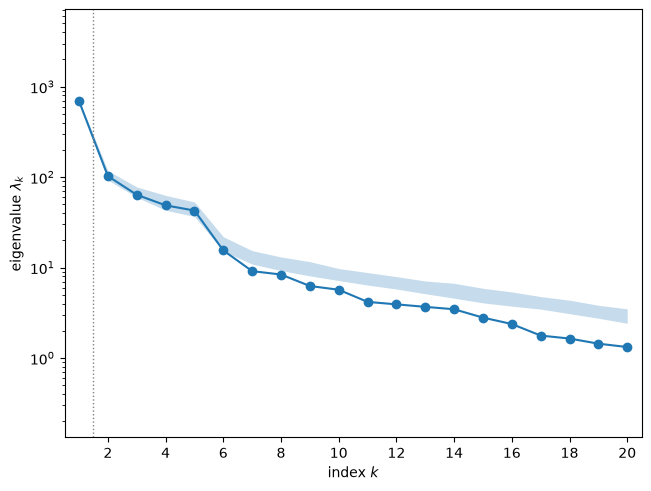

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub, k_max=20)
plt.close(fig)
lo, hi = np.percentile(sub.bootstrap_eigenvalues[:, :4], [2.5, 97.5], axis=0)
print('95% bootstrap intervals, l1..l4:', '; '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo, hi)))
fig

$\lambda_1 = 692.3$ stands well above $\lambda_2 = 102.6$ ($\lambda_1/\lambda_2 = 6.75$, bootstrap intervals [679, 717] and [92.8, 118] do not overlap), while $\lambda_2, \lambda_3, \lambda_4, \lambda_5$ (102.6, 63.9, 48.8, 42.7) decay slowly ($\lambda_2/\lambda_3 = 1.61$), so the gap rule picks $n = 1$. The first eigenvalue is 67.1 % of the trace of $\hat{\mathbf C}$; this is a property of the fitted quadratic, and the next cells show that it is not robust. The quadratic explains 86.3 % of the variance of the held-out samples (a linear fit explains 79.0 % in-sample), and the OLS direction is almost the same as $\mathbf w_1$ ($|\mathbf w_{1,\rm OLS}^T\mathbf w_1| = 0.998$): the dominant direction is mostly a linear trend.

In [7]:
# w1 and the eigenvalue split under other estimates of the gradients
for p in (73, 86):                                               # local-linear fits, p nearest samples each
    gl = ac.local_linear_gradients(X=X, f=f, space=space, p=p)
    s_ll = ac.active_subspace(space=space, grads=gl, estimator='as', nboot=0)
    print(f'local-linear gradients, p = {p}: |w1(LL) . w1(QPHD)| = {abs(s_ll.W[:, 0] @ sub.W[:, 0]):.3f}, '
          f'l1/l2 = {s_ll.eigenvalues[0] / s_ll.eigenvalues[1]:.1f}')
c_q, *_ = np.linalg.lstsq(quad_design(Xn), f, rcond=None)      # the quadratic behind QPHD
g_q = c_q[1:m + 1]
H_q = np.diag(2 * c_q[m + 1:2 * m + 1])
ju, ku = np.triu_indices(m, k=1)
H_q[ju, ku] = H_q[ku, ju] = c_q[2 * m + 1:]
for row, gfd in zip(G_fd[:, 0].astype(int), G_fd[:, 1:]):
    gq = g_q + H_q @ Xn[row]
    print(f'row {row}: finite-difference gradient: share of |grad|^2 on w1 {(sub.W[:, 0] @ gfd) ** 2 / (gfd @ gfd):.1%}, '
          f'on span(w1, w2) {np.sum((sub.W[:, :2].T @ gfd) ** 2) / (gfd @ gfd):.1%}; '
          f'cosine with the quadratic\'s gradient {gfd @ gq / np.linalg.norm(gfd) / np.linalg.norm(gq):.2f}')
print(f'QPHD trace share of l2..l10: {lam[1:10].sum() / lam.sum():.1%}')


def poly_in(Y):
    """1, y, y^2, cross terms and cubes of the active variables."""
    a, b = np.triu_indices(Y.shape[1], k=1)
    return np.hstack([np.ones((len(Y), 1)), Y, Y ** 2, Y[:, a] * Y[:, b], Y ** 3])


for k in (1, 2, 3, 5, 10):
    A = poly_in(Xn @ sub.W[:, :k])
    ck, *_ = np.linalg.lstsq(A[:3072], f[:3072], rcond=None)
    r = f[3072:] - A[3072:] @ ck
    print(f'quadratic + cubes in the first {k:2d} QPHD active variables: hold-out R^2 = '
          f'{1 - r @ r / np.sum((f[3072:] - f[3072:].mean()) ** 2):.3f}')

local-linear gradients, p = 73: |w1(LL) . w1(QPHD)| = 0.997, l1/l2 = 46.2


local-linear gradients, p = 86: |w1(LL) . w1(QPHD)| = 0.997, l1/l2 = 54.7


row 0: finite-difference gradient: share of |grad|^2 on w1 64.4%, on span(w1, w2) 65.9%; cosine with the quadratic's gradient 0.90
row 1: finite-difference gradient: share of |grad|^2 on w1 42.7%, on span(w1, w2) 46.5%; cosine with the quadratic's gradient 0.83
row 2: finite-difference gradient: share of |grad|^2 on w1 23.5%, on span(w1, w2) 24.1%; cosine with the quadratic's gradient 0.72
QPHD trace share of l2..l10: 29.4%
quadratic + cubes in the first  1 QPHD active variables: hold-out R^2 = 0.788
quadratic + cubes in the first  2 QPHD active variables: hold-out R^2 = 0.823
quadratic + cubes in the first  3 QPHD active variables: hold-out R^2 = 0.858
quadratic + cubes in the first  5 QPHD active variables: hold-out R^2 = 0.897
quadratic + cubes in the first 10 QPHD active variables: hold-out R^2 = 0.918


**How robust is this?** The direction is; the split is not. Local-linear gradients (`ac.local_linear_gradients`, 73 or 86 nearest samples per fit) give a leading eigenvector within $|\cos| = 0.997$ of $\mathbf w_1$, as the OLS direction does (0.998), but a much larger $\lambda_1/\lambda_2$ (46.2 and 54.7): near-global linear fits in 43 dimensions mostly see the linear trend. Finite-difference gradients at design rows 0, 1 and 2 point the other way: they put only 64.4 %, 42.7 % and 23.5 % of their squared norm on $\mathbf w_1$ (65.9 %, 46.5 % and 24.1 % on span($\mathbf w_1, \mathbf w_2$)), and their cosines with the quadratic's gradient are only 0.90, 0.83 and 0.72, because the quadratic misses local effects such as a thin topsoil. Values agree with that picture: a polynomial in $y_1$ alone explains 78.8 % of the held-out variance, and adding directions 2–10 raises this slowly to 82.3 %, 85.8 %, 89.7 % and 91.8 % ($k$ = 2, 3, 5, 10), so about a fifth of the variance lies in a slowly decaying tail ($\lambda_2, \dots, \lambda_{10}$ hold 29.4 % of the trace). We keep $n = 1$ as a useful approximate ridge with a trustworthy $\mathbf w_1$, and read $\lambda_1/\lambda_2 = 6.75$ and the 67.1 % as properties of the fitted quadratic, not of $\mathbb E[\nabla f\,\nabla f^T]$.

bootstrap mean subspace distance, k = 1..4: [0.042 0.141 0.257 0.457]


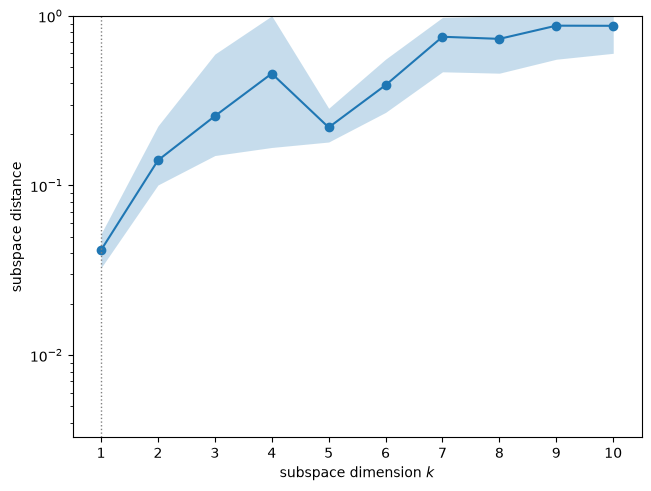

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=10)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..4:', np.array2string(sub.bootstrap_distances.mean(axis=0)[:4], precision=3))
fig

The bootstrap mean distance between the estimated and replicated subspaces is 0.042 for $k = 1$ and grows to 0.141, 0.257 and 0.457 for $k = 2, 3, 4$: the one-dimensional subspace is well determined by the 4096 samples, the next directions are not.

w1: x06 -0.637, x08 -0.466, x05 +0.296, x33 +0.269, r5 -0.228, r3 -0.225
w2: x08 -0.838, x06 +0.449, x05 -0.188, r4 +0.140, r5 +0.105, x33 +0.068
share of |w1|^2 on the 8 weight numbers r1..r8: 0.137


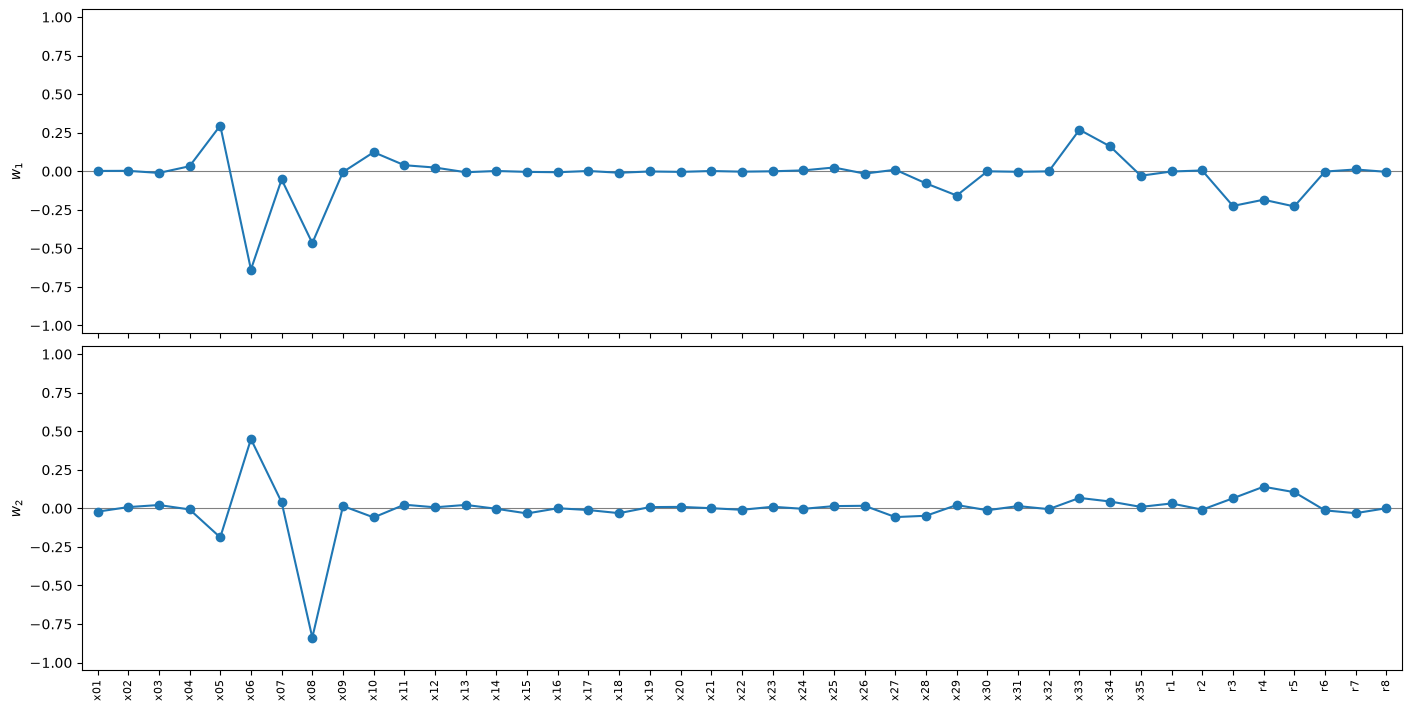

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=names, figsize=(14, 7))
for a in axes:
    a.tick_params(axis='x', labelrotation=90, labelsize=8)
plt.close(fig)


def top(w, k=6):
    o = np.argsort(-np.abs(w))[:k]
    return ', '.join(f'{names[i]} {w[i]:+.3f}' for i in o)


print('w1:', top(sub.W[:, 0]))
print('w2:', top(sub.W[:, 1]))
print(f'share of |w1|^2 on the 8 weight numbers r1..r8: {np.sum(sub.W[35:, 0] ** 2):.3f}')
fig

$\mathbf w_1$ is led by the topsoil quickflow exponent $x_6$ ($-0.637$), the PET correction $x_8$ ($-0.466$), the maximum quickflow rate $x_5$ ($+0.296$) and the rain correction $x_{33}$ ($+0.269$), followed by the evaporation and quickflow weight numbers $r_5$ ($-0.228$) and $r_3$ ($-0.225$); the eight weight numbers together hold 13.7 % of $\|\mathbf w_1\|^2$. The signs read as a water balance: more rain ($x_{33}$) and faster quickflow ($x_5$ up, $x_6$ down) send more water to the river before it can evaporate, and a larger PET correction ($x_8$) removes more. $\mathbf w_2$ is mostly $x_8$ ($-0.838$) against $x_6$ ($+0.449$). The snow and melt parameters and the routing (convolution) parameters have weights near zero: over 20 years they shift *when* water reaches the river, not *how much*.

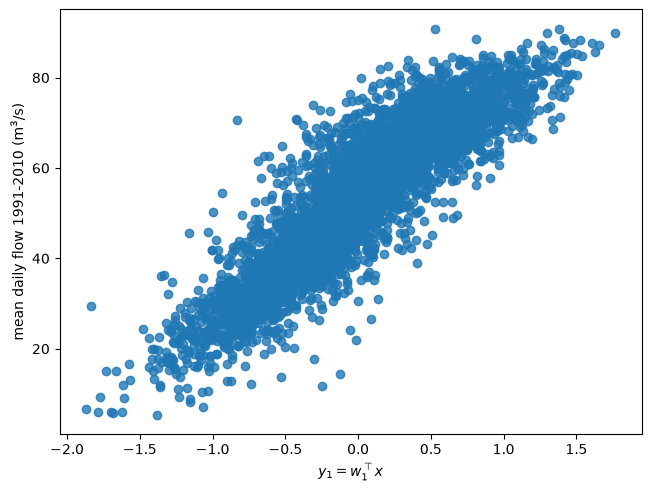

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='mean daily flow 1991-2010 (m$^3$/s)')
plt.close(fig)
fig

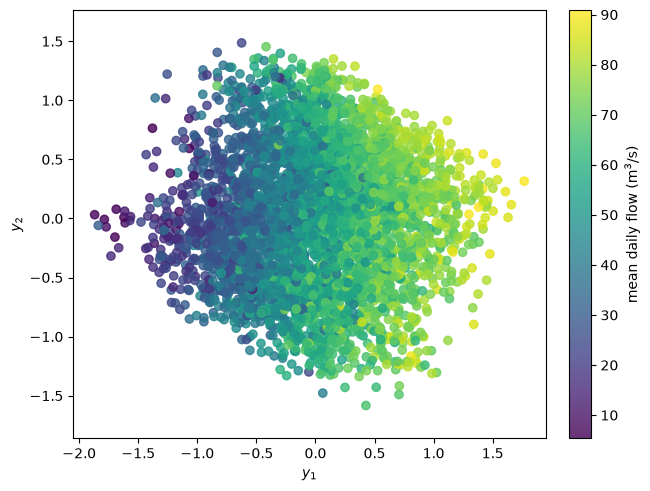

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label='mean daily flow (m$^3$/s)')
plt.close(fig)
fig

The one-dimensional summary plot shows a clear, nearly linear trend from about 5 to 90 m³/s with a vertical spread of roughly ±10 m³/s; in the two-dimensional plot the colour changes mainly along $y_1$. The spread is the part of the mean flow that one direction misses.

corr(mean_Q, y1) = 0.887
polynomial of degree 3 in 1 active variable(s): LOO R^2 = 0.7989
polynomial of degree 3 in 2 active variable(s): LOO R^2 = 0.8354


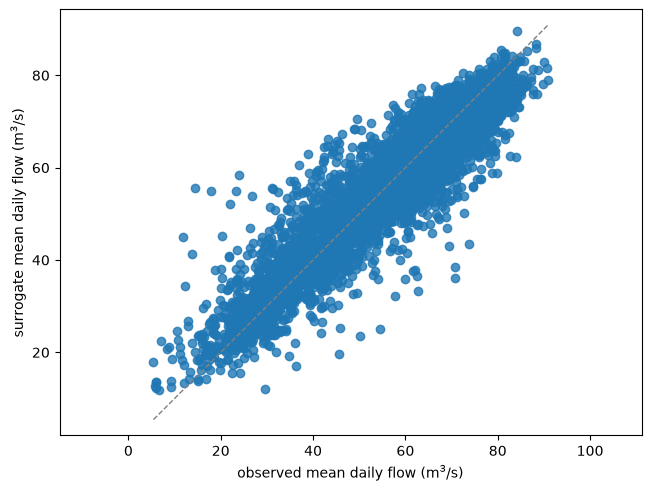

In [12]:
y1 = Xn @ sub.W[:, 0]
print(f'corr(mean_Q, y1) = {np.corrcoef(f, y1)[0, 1]:.3f}')
sur = {}
for k, deg in [(1, 3), (2, 3)]:
    s_k = ac.with_dimension(sub, k)
    sur[k] = ac.fit_surrogate(X=X, f=f, space=space, subspace=s_k, kind='poly', degree=deg)
    print(f'polynomial of degree {deg} in {k} active variable(s): LOO R^2 = {sur[k].loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur[2], X=X, f=f, qoi_label='mean daily flow (m$^3$/s)')
plt.close(fig)
fig

A cubic in $y_1$ reaches a leave-one-out $R^2$ of 0.799 and a cubic in $(y_1, y_2)$ 0.835 (figure: predicted against Raven's mean flow), in line with the correlation 0.887 between $\bar Q$ and $y_1$. One or two active variables capture about four fifths of the variability of the mean flow over 43 inputs, which is useful but not a tight ridge function.

### Results: Nash–Sutcliffe efficiency

The same analysis for the NSE of simulated against observed daily flow (5863 days of 1991–2010 with observations, counted by Raven's period-ending row dates, so the row dated 1991-01-01 holds the flow of 31 December 1990; the monthly means below use the same dates). Note that 91.6 % of the samples overestimate the observed mean flow of 29.26 m³/s, so most of the box is poor in NSE terms (median −4.15; 13 samples above 0.5).

QPHD on NSE: n = 1 (EVG rule), 155 s
eigenvalues 1-6: [24.8748  3.911   3.5401  2.0832  1.3725  0.8296]
l1/l2 = 6.36, l2/l3 = 1.10; bootstrap mean subspace distance k = 1, 2: 0.049, 0.376


quadratic fit hold-out R^2 = 0.8456
w1: x06 +0.538, r3 +0.391, x05 -0.339, x29 +0.333, r4 +0.321, x25 -0.295
w2: r3 +0.757, x06 -0.447, x05 +0.385, r4 -0.131, x25 -0.127, x34 -0.102
|w1(NSE) . w1(mean_Q)| = 0.827


local-linear gradients (p = 86): |w1(LL) . w1(QPHD)| = 0.998, l1/l2 = 49.7
cubic in 2 active variables: LOO R^2 = 0.7947


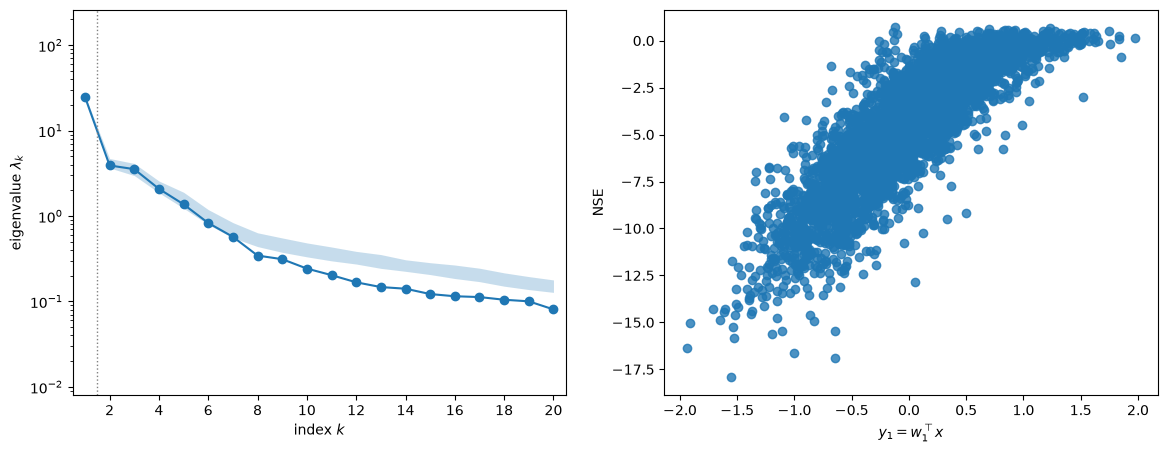

In [13]:
t0 = time.perf_counter()
g = F[:, 1]                                                     # NSE
sub_n = ac.active_subspace(space=space, X=X, f=g, estimator='qphd', nboot=200, rng=SEED)
sub_n = ac.orient(sub_n, by='covariance', X=X, f=g, columns=2)
ln = sub_n.eigenvalues
print(f'QPHD on NSE: n = {sub_n.n} (EVG rule), {time.perf_counter() - t0:.0f} s')
print('eigenvalues 1-6:', np.array2string(ln[:6], precision=4))
print(f'l1/l2 = {ln[0] / ln[1]:.2f}, l2/l3 = {ln[1] / ln[2]:.2f}; bootstrap mean subspace distance k = 1, 2: '
      f'{sub_n.bootstrap_distances.mean(axis=0)[0]:.3f}, {sub_n.bootstrap_distances.mean(axis=0)[1]:.3f}')
print(f'quadratic fit hold-out R^2 = {holdout_r2(Xn, g):.4f}')
print('w1:', top(sub_n.W[:, 0]))
print('w2:', top(sub_n.W[:, 1]))
print(f'|w1(NSE) . w1(mean_Q)| = {abs(sub_n.W[:, 0] @ sub.W[:, 0]):.3f}')
s_lln = ac.active_subspace(space=space, grads=ac.local_linear_gradients(X=X, f=g, space=space, p=86),
                           estimator='as', nboot=0)
print(f'local-linear gradients (p = 86): |w1(LL) . w1(QPHD)| = {abs(s_lln.W[:, 0] @ sub_n.W[:, 0]):.3f}, '
      f'l1/l2 = {s_lln.eigenvalues[0] / s_lln.eigenvalues[1]:.1f}')
sur_n = ac.fit_surrogate(X=X, f=g, space=space, subspace=ac.with_dimension(sub_n, 2), kind='poly', degree=3)
print(f'cubic in 2 active variables: LOO R^2 = {sur_n.loo_r_squared:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ac.plotting.plot_eigenvalues(sub_n, k_max=20, ax=axes[0])
ac.plotting.plot_sufficient_summary(sub_n, X=X, f=g, dims=1, qoi_label='NSE', ax=axes[1])
plt.close(fig)
fig

The NSE also has one leading direction in the QPHD estimate: $\lambda_1/\lambda_2 = 6.36$ (like the mean flow's split, a property of the fitted quadratic; local-linear gradients give a direction within $|\cos| = $ 0.998 and $\lambda_1/\lambda_2 = $ 49.7), with $\lambda_2$ and $\lambda_3$ nearly equal ($\lambda_2/\lambda_3 = 1.10$), bootstrap mean distance 0.049 for $k = 1$ and 0.376 for $k = 2$, and a quadratic hold-out $R^2$ of 0.846. $\mathbf w_1$ is led by $x_6$ (+0.538), the quickflow weight numbers $r_3$ (+0.391) and $r_4$ (+0.321), $x_5$ (−0.339), the topsoil thickness $x_{29}$ (+0.333) and the melt factor increment $x_{25}$ (−0.295); it is close to the mean-flow direction with the opposite sign ($|\mathbf w_1^T\mathbf w_{1,\bar Q}| = 0.827$), because most samples are too wet and the NSE rises as the simulated water balance falls toward the observed one. The summary plot rises to a plateau near NSE = 0 and fans out at low $y_1$, so the NSE is a ridge function only in its trend; a cubic in two active variables gives a LOO $R^2$ of 0.795. In the eigenvalue plot the bootstrap band lies above the estimates from $k \approx 8$ on: resampling with repeats makes the 990-coefficient quadratic fit noise, which inflates the small eigenvalues, so the tail of the spectrum should not be read.

### Results by calendar month and comparison with process sensitivities

The paper's sensitivities are of daily flow, averaged with weights proportional to the output variance of each day, so they are dominated by the spring freshet (Fig. 6). Our closest analogue is the mean flow of each calendar month over 1991–2010. The next cell estimates QPHD for each month (no bootstrap), and then forms process shares: for each process of Table C1, the sum of the diagonal entries of $\hat{\mathbf C}$ over its parameters (the mean squared derivative of the quadratic, a derivative-based sensitivity measure), normalized to sum to 1. Like the paper's process sensitivities these exclude the weight numbers $r_i$, and $x_{29}$ counts in each of the four processes it belongs to (Table C1). Summing $\hat{\mathbf C}$ over the 12 months weights each month by the size of its derivatives, as the paper's variance weights favour high-variance days. These shares are not Sobol' indices, and they depend on how each input is scaled (here by its half-range; $x_4$ and $x_{11}$ on their log10 scale, as sampled), so only their pattern can be compared with the paper.

In [14]:
groups = {  # Table C1: the parameters of each process (x29 belongs to M, N, O and U, as in the paper)
    'M infiltration': ['x01', 'x02', 'x03', 'x29'], 'N quickflow': ['x04', 'x05', 'x06', 'x07', 'x29'],
    'O evaporation': ['x08', 'x09', 'x10', 'x29'], 'P baseflow': ['x11', 'x12'],
    'Q snow balance': [f'x{i}' for i in range(13, 20)], 'R conv. surface': ['x20', 'x21'],
    'S conv. delayed': ['x22', 'x23'], 'T potential melt': ['x24', 'x25', 'x26', 'x27'],
    'U percolation': ['x28', 'x29', 'x30', 'x35'], 'V rain-snow': ['x31', 'x32'], 'W precip. corr.': ['x33', 'x34']}


def qphd_C(y):
    """The QPHD matrix g g^T + H Sigma H (normalized coordinates, Sigma = I/3), as in the library."""
    c, *_ = np.linalg.lstsq(quad_design(Xn), y, rcond=None)
    gr = c[1:m + 1]
    H = np.diag(2 * c[m + 1:2 * m + 1])
    ju, ku = np.triu_indices(m, k=1)
    H[ju, ku] = H[ku, ju] = c[2 * m + 1:]
    return np.outer(gr, gr) + H @ H / 3


def shares(C):
    d = np.diag(C)
    s = np.array([sum(d[names.index(p)] for p in ps) for ps in groups.values()])
    return s / s.sum()


t0 = time.perf_counter()
C_mon = []
print(f"{'month':5s} {'median Q':>8s} {'n':>2s} {'l1/l2':>6s} {'l2/l3':>6s} {'R2 hold':>7s}  leading entries of w1")
for k, mo in enumerate(months):
    y = F[:, 3 + k]
    s_m = ac.active_subspace(space=space, X=X, f=y, estimator='qphd', nboot=0)
    s_m = ac.orient(s_m, by='covariance', X=X, f=y, columns=1)
    C_mon.append(qphd_C(y))
    lm = s_m.eigenvalues
    print(f'{mo:5s} {np.median(y):8.1f} {s_m.n:2d} {lm[0] / lm[1]:6.2f} {lm[1] / lm[2]:6.2f} {holdout_r2(Xn, y):7.3f}  {top(s_m.W[:, 0], 4)}')
print(f'check: own QPHD matrix vs the library for December, max eigenvalue difference '
      f'{np.abs(np.linalg.eigvalsh(C_mon[-1])[::-1] - s_m.eigenvalues).max():.1e}; {time.perf_counter() - t0:.0f} s')
S_mon = np.array([shares(C) for C in C_mon])
s_sum = shares(sum(C_mon))
s_mean = shares(qphd_C(f))
print(f"\n{'process':17s} {'mean_Q':>7s} {'sum of 12 months':>17s}")
for gname, a, b in zip(groups, s_mean, s_sum):
    print(f'{gname:17s} {a:7.1%} {b:17.1%}')
print(f"evaporation share, mean over June-October: {S_mon[5:10, 2].mean():.1%}")
d_sum = np.diag(sum(C_mon))
rank = np.argsort(-d_sum)
print('inputs ranked by diag of the summed monthly C (share):',
      ', '.join(f'{names[i]} {d_sum[i] / d_sum.sum():.1%}' for i in rank[:16]))
paper13 = ['x05', 'x06', 'x08', 'x16', 'x18', 'x19', 'x24', 'x25', 'x26', 'x27', 'x29', 'x31', 'x34']
top_x = [names[i] for i in rank if names[i].startswith('x')][:13]
print(f"paper's 13 most sensitive parameters found among our top 13 parameters: {len(set(top_x) & set(paper13))} "
      f"({', '.join(sorted(set(top_x) & set(paper13)))}); ours not in the paper's list: {', '.join(sorted(set(top_x) - set(paper13)))}")
d_mean = np.diag(qphd_C(f))
top_x_mean = [names[i] for i in np.argsort(-d_mean) if names[i].startswith('x')][:13]
print(f"same count for the 20-year mean flow alone: {len(set(top_x_mean) & set(paper13))} "
      f"({', '.join(sorted(set(top_x_mean) & set(paper13)))})")
r_rank = [names[i] for i in rank if names[i].startswith('r')]
print('weight numbers ranked:', ', '.join(r_rank))
for lab, s in [('mean_Q', s_mean), ('sum of months', s_sum)]:
    print(f'{lab}: T+V+W {s[[7, 9, 10]].sum():.1%}, N+Q {s[[1, 4]].sum():.1%}, M+O+U {s[[0, 2, 8]].sum():.1%}, '
          f'P+R+S {s[[3, 5, 6]].sum():.1%}')

month median Q  n  l1/l2  l2/l3 R2 hold  leading entries of w1


Jan       17.5  1   9.81   1.83   0.905  x26 -0.737, x24 +0.345, r7 +0.302, x25 +0.274


Feb       27.8  1   6.64   3.08   0.888  x26 -0.718, x25 +0.364, r7 +0.301, x24 +0.287


Mar       85.9  1   4.25   1.41   0.825  x26 -0.485, x06 -0.419, x25 +0.391, r7 +0.295


Apr      136.1  1   5.61   2.81   0.842  x26 +0.608, x34 +0.395, x06 -0.248, x25 -0.245


May       44.2  1   4.85   1.32   0.766  x26 +0.465, x08 -0.431, x25 -0.387, x24 -0.312


... (5 outputs left out)

Nov       51.3  1   2.36   3.75   0.771  x31 -0.560, x33 +0.432, x08 -0.366, x26 -0.364


Dec       17.1  1   5.81   1.85   0.784  x26 -0.731, x31 -0.321, x24 +0.276, r7 +0.197
check: own QPHD matrix vs the library for December, max eigenvalue difference 3.3e-13; 27 s



process            mean_Q  sum of 12 months
M infiltration       5.9%              4.6%
N quickflow         46.9%             29.9%
O evaporation       29.5%             19.2%
P baseflow           0.5%              0.5%
Q snow balance       0.9%              3.7%
R conv. surface      0.3%              0.4%
S conv. delayed      0.1%              0.3%
T potential melt     0.6%             26.5%
U percolation        6.7%              5.0%
V rain-snow          0.5%              1.8%
W precip. corr.      8.1%              8.0%
evaporation share, mean over June-October: 31.6%
inputs ranked by diag of the summed monthly C (share): x06 17.7%, x26 13.8%, x08 13.0%, x05 6.2%, x25 6.2%, r3 5.1%, r7 4.8%, x34 4.4%, x29 4.0%, x33 3.3%, x24 3.1%, r5 2.9%, r4 2.3%, x27 2.3%, x31 1.5%, x19 1.3%
paper's 13 most sensitive parameters found among our top 13 parameters: 11 (x05, x06, x08, x19, x24, x25, x26, x27, x29, x31, x34); ours not in the paper's list: x10, x33


same count for the 20-year mean flow alone: 6 (x05, x06, x08, x29, x31, x34)
weight numbers ranked: r3, r7, r5, r4, r8, r6, r1, r2
mean_Q: T+V+W 9.2%, N+Q 47.8%, M+O+U 42.1%, P+R+S 0.9%
sum of months: T+V+W 36.4%, N+Q 33.6%, M+O+U 28.9%, P+R+S 1.2%


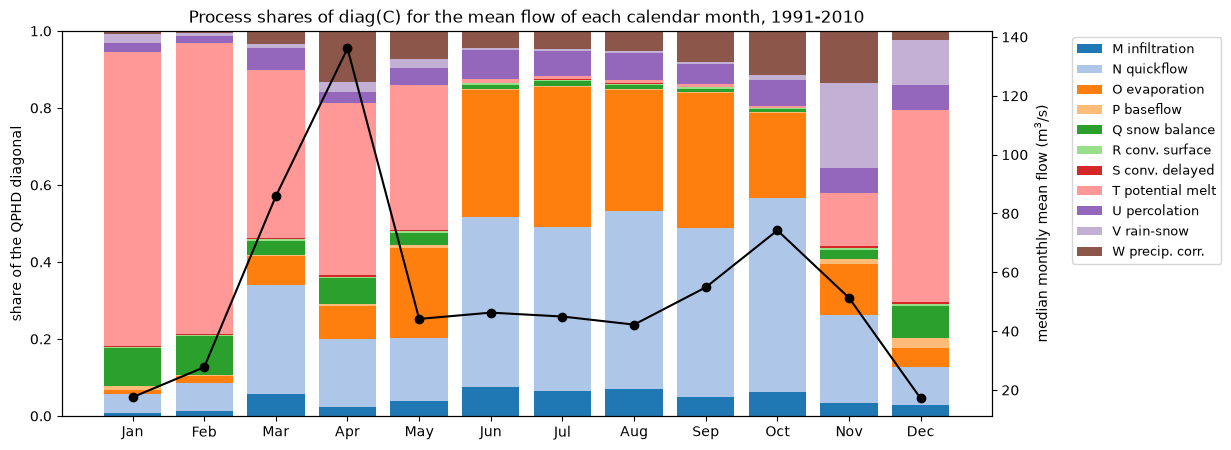

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
cmap = plt.get_cmap('tab20')
bottom = np.zeros(12)
for j, gname in enumerate(groups):
    ax.bar(months, S_mon[:, j], bottom=bottom, color=cmap(j), label=gname)
    bottom += S_mon[:, j]
ax2 = ax.twinx()
ax2.plot(months, np.median(F[:, 3:], axis=0), 'k-o', label='median monthly flow')
ax2.set_ylabel('median monthly mean flow (m$^3$/s)')
ax.set_ylabel('share of the QPHD diagonal')
ax.set_ylim(0, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1.08, 1), fontsize=9)
ax.set_title('Process shares of diag(C) for the mean flow of each calendar month, 1991-2010')
plt.close(fig)
fig

Each month has $n = 1$ by the gap rule, with $\lambda_1/\lambda_2$ from 2.36 (November) to 10.43 (October) and quadratic hold-out $R^2$ from 0.766 to 0.905. The leading inputs change with the season: in December–February the melt temperature $x_{26}$ leads $\mathbf w_1$ (weights −0.718 to −0.737), with the other melt parameters and the snow-balance number $r_7$; in March–May the melt parameters share $\mathbf w_1$ with $x_6$, $x_8$ and the snow correction $x_{34}$; in June–October $x_6$ and $x_8$ lead, as for the 20-year mean; in November the rain–snow temperature $x_{31}$ leads. The figure shows the same as process shares: potential melt (T) dominates from December to February and is large through May, quickflow (N) and evaporation (O) dominate from June to October (evaporation 31.6 % on average over June–October; the paper reports about 35.4 % for June to October), and baseflow (P) and the two convolutions (R, S) are almost invisible all year, as in the paper's Fig. 6. Summed over the months, potential melt, rain–snow partitioning and precipitation correction (T + V + W) carry 36.4 %, quickflow and snow balance (N + Q) 33.6 %, infiltration, evaporation and percolation (M + O + U) 28.9 % and baseflow and convolution (P + R + S) 1.2 %, against the paper's 42.1 %, 38.5 %, 19.2 % and 0.2 % (Sobol' total indices of daily flow). For the 20-year mean flow the same shares are 9.2 %, 47.8 %, 42.1 % and 0.9 %: the melt processes matter for timing, not for the long-term volume. By the same diagonal, summed over the months, 11 of the paper's 13 most sensitive parameters are among our 13 leading parameters (all but $x_{16}$ and $x_{18}$, the HMETS refreeze parameters; ours add $x_{10}$ and $x_{33}$), and $r_3$ and $r_7$ are the leading weight numbers, as in the paper ($r_3$, $r_4$, $r_7$). For the 20-year mean flow alone the overlap is only 6 of 13, since the melt parameters drop out.

### Comparison with the paper

The paper does no active-subspace analysis, and its Sobol' indices are shown in bar charts (Figs. 5, 6) with only a few numbers in the text, so the comparison is of rankings and process shares. Our design, QoIs and Raven build differ from the paper's (see `DATA.md`; the paper's Raven revision is not known and was possibly a 2.9.x build).

| quantity | paper | notebook |
|---|---|---|
| number of inputs | 43 (35 parameters + 8 weight numbers; Table C2, Sect. 2.1.2) | 43, same ranges |
| model runs | 45 000 (xSSA, K = 1000) | 4096 (scrambled Sobol') |
| QoI | daily streamflow 1991–2010, variance-weighted | mean flow 1991–2010; NSE; 12 monthly mean flows |
| active subspace of the mean flow | not reported | $n = 1$; $\mathbf w_1$ robust ($\ge 0.997$ vs OLS and local-linear); $\lambda_1/\lambda_2 = 6.75$ (QPHD), 46.2–54.7 (local-linear); finite-difference gradients put 23.5–64.4 % on $\mathbf w_1$ |
| active subspace of the NSE | not reported | $n = 1$, $\lambda_1/\lambda_2 = 6.36$ (QPHD) |
| most sensitive parameters | $x_{24}$–$x_{27}$ (potential melt), then $x_5$, $x_6$ | mean flow: $x_6$, $x_8$, $x_5$, $x_{33}$; summed months: $x_6$, $x_{26}$, $x_8$, $x_5$, $x_{25}$ |
| 13 parameters carrying 96.5 % (paper) | $x_5, x_6, x_8, x_{16}, x_{18}, x_{19}, x_{24}$–$x_{27}, x_{29}, x_{31}, x_{34}$ | 11 of them in our top 13 (summed months; not $x_{16}$, $x_{18}$); 6 for the mean flow alone |
| most influential weight numbers | $r_3$, $r_4$, $r_7$ | summed months: $r_3$, $r_7$, $r_5$, $r_4$ |
| T + V + W / N + Q / M + O + U / P + R + S | 42.1 % / 38.5 % / 19.2 % / 0.2 % (Sobol') | 36.4 % / 33.6 % / 28.9 % / 1.2 % (QPHD diagonal, summed months) |
| evaporation share, June–October | about 35.4 % | 31.6 % (monthly mean flows) |
| baseflow and convolution | negligible | 1.2 % in total |

The structure we find is consistent with the paper's conclusions: the processes that move water into or out of the model (melt, precipitation correction, quickflow, evaporation) matter, the routing and deep baseflow do not, and the quickflow and snow-balance weights matter most among the structural choices. The headline difference is the QoI: for the 20-year mean flow the melt parameters, which lead the paper's ranking of daily flow, almost drop out.

In [16]:
print(f'run time of this notebook: {time.perf_counter() - t_start:.0f} s')

run time of this notebook: 375 s


### References

[1] J. Mai, J. R. Craig, and B. A. Tolson. Simultaneously determining global sensitivities of model parameters and model structure. *Hydrology and Earth System Sciences*, 24(12):5835–5858, 2020. [doi:10.5194/hess-24-5835-2020](https://doi.org/10.5194/hess-24-5835-2020)

[2] J. R. Craig, G. Brown, R. Chlumsky, R. W. Jenkinson, G. Jost, K. Lee, J. Mai, M. Serrer, N. Sgro, M. Shafii, A. P. Snowdon, and B. A. Tolson. Flexible watershed simulation with the Raven hydrological modelling framework. *Environmental Modelling & Software*, 129:104728, 2020. [doi:10.1016/j.envsoft.2020.104728](https://doi.org/10.1016/j.envsoft.2020.104728)

[3] A. Moeini, B. Abbasi, and H. Mahlooji. Conditional distribution inverse method in generating uniform random vectors over a simplex. *Communications in Statistics – Simulation and Computation*, 40(5):685–693, 2011. [doi:10.1080/03610918.2010.551012](https://doi.org/10.1080/03610918.2010.551012)

[4] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

Code and data of the paper: [github.com/julemai/xSSA](https://github.com/julemai/xSSA) (archived as doi:10.5281/zenodo.4301003). Raven source: [github.com/CSHS-CWRA/RavenHydroFramework](https://github.com/CSHS-CWRA/RavenHydroFramework).

### Acknowledgments

The paper's research was undertaken thanks in part to funding from the CANARIE research software funding program (project RS-332), with computing facilities of SHARCNET and Compute/Calcul Canada and support from the Canadian Foundation for Innovation John Evans Leaders Fund (paper, Acknowledgements and Financial support).